# Desafio, estimar a participação das ações no indice Ibovespa

A nova carteira do Ibovespa, que é válida até 29 de dezembro de 2023, teve como base o pregão de 1 de setembro.

In [1]:
import pandas as pd

dfMemb = pd.read_csv('IBOVQuad_9-2023.csv')
dfMemb = dfMemb.iloc[:-2,:]
dfMemb.sort_values(by='perc',ascending=False).head(10)
dfMemb.qty = [int(x.replace('.','')) for x in dfMemb.qty]

In [2]:
dfMemb = dfMemb.drop('Unnamed: 5',axis=1)

In [3]:
listMemb = list(dfMemb.ticker)
# listMemb = listMemb[:-2]


In [4]:
from pandas_datareader import data as pdr

import yfinance as yf
yf.pdr_override() # <== that's all it takes :-)

# download dataframe
# data = pdr.get_data_yahoo("SPY", start="2017-01-01", end="2017-04-30")
dfAll = pd.DataFrame()
for ticker in listMemb:
    df = pdr.get_data_yahoo(ticker + ".SA", start="2023-01-01", end="2024-01-02")
    dfAdCl = df.loc[:,['Adj Close']]
    dfAdCl.columns = [ticker + ".SA"]
    if dfAll.empty:
        dfAll = dfAdCl.copy()
    else:
        dfAll = pd.concat([dfAll,dfAdCl],axis=1)


[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed


1 Failed download:
['ALSO3.SA']: Exception('%ticker%: No timezone found, symbol may be delisted')



[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%******


1 Failed download:
['VIIA3.SA']: Exception('%ticker%: No timezone found, symbol may be delisted')



[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed


In [5]:
dfIbov = pdr.get_data_yahoo("^BVSP", start="2023-01-01", end="2023-12-30")
dfIbov

[*********************100%%**********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2023-01-02,109734.0,109734.0,105981.0,106376.0,106376.0,8130500
2023-01-03,106377.0,106684.0,103852.0,104166.0,104166.0,14466700
2023-01-04,104167.0,105627.0,103915.0,105334.0,105334.0,14451200
2023-01-05,105336.0,107743.0,105333.0,107518.0,107518.0,15512000
2023-01-06,107642.0,109433.0,107642.0,108836.0,108836.0,12626600
...,...,...,...,...,...,...
2023-12-21,130826.0,132277.0,130822.0,132182.0,132182.0,8681000
2023-12-22,132553.0,133035.0,132094.0,132753.0,132753.0,8231100
2023-12-26,132753.0,133645.0,132753.0,133533.0,133533.0,0


### check stocks without data

In [6]:
dfAll.isna().all()[dfAll.isna().all()]

ALSO3.SA    True
VIIA3.SA    True
dtype: bool

In [7]:
dfAll.columns = [x.replace('.SA','') for x in dfAll.columns]
dfAll

,ABEV3,ALPA4,ALSO3,ARZZ3,ASAI3,AZUL4,B3SA3,BBAS3,BBDC3,BBDC4,...,TOTS3,UGPA3,USIM5,VALE3,VAMO3,VBBR3,VIIA3,VIVT3,WEGE3,YDUQ3
Date,,,,,,,,,,,,,,,,,,,,,
2023-01-02,13.485133,14.33,NaN,71.978569,18.912775,10.300000,11.856249,30.695688,11.945461,13.384404,...,25.528303,11.703218,6.705389,84.082291,11.207919,14.119396,NaN,34.708275,37.490425,9.670109
2023-01-03,13.466127,13.40,NaN,69.735306,18.534321,10.160000,11.459429,30.123495,11.380733,12.720203,...,24.650738,11.517143,6.629083,83.931808,10.570777,13.696775,NaN,34.012012,36.555630,9.057701
2023-01-04,13.542153,13.49,NaN,71.337631,19.002409,10.560000,11.546535,30.511112,11.480484,12.756549,...,25.370539,11.791360,6.762619,84.082291,10.831427,14.100186,NaN,34.755962,36.801624,9.176231
2023-01-05,13.580167,13.86,NaN,72.192207,18.902815,11.550000,11.904643,31.904690,11.852285,13.310786,...,26.524193,11.948055,7.163225,85.493065,11.101728,14.167421,NaN,35.690674,36.880348,9.294762
2023-01-06,13.608676,13.87,NaN,73.610031,18.962574,11.840000,12.185321,32.347683,12.169679,13.683306,...,26.958048,12.085166,7.239531,86.847412,11.516836,14.263473,NaN,36.453705,37.421547,9.630598
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-21,13.700000,9.13,NaN,66.160004,13.240000,16.410000,14.389895,54.290001,14.995547,16.758947,...,33.349998,26.260000,9.130000,76.970001,9.790000,21.949247,NaN,52.691864,36.389999,22.920000
2023-12-22,13.710000,9.50,NaN,66.650002,13.410000,16.299999,14.409758,54.439999,15.032819,16.810934,...,32.849998,26.299999,9.280000,76.389999,9.730000,22.106379,NaN,53.068233,36.509998,22.280001
2023-12-26,13.770000,9.75,NaN,66.400002,13.370000,16.260000,14.558721,54.939999,15.092750,16.860876,...,33.529999,26.370001,9.320000,76.660004,9.800000,22.350000,NaN,53.335651,36.720001,22.400000


In [8]:
dfAll.index = pd.to_datetime(dfAll.index)

In [9]:
dfAll = dfAll.dropna(axis=1,how='all')

In [10]:
dfMemb = dfMemb.set_index('ticker')


In [11]:
dfQty = pd.DataFrame( dfAll.shape[0]*[dfMemb.qty.to_list()], index = dfAll.index,columns = dfMemb.index)

In [12]:
dfNotional = dfAll*dfQty

In [13]:
dfNotional = dfNotional.dropna(how='all',axis=1)


In [14]:
dfNotional.index = pd.to_datetime(dfNotional.index)

In [15]:
dfRet = dfNotional.sum(axis=1)
dfRet = pd.DataFrame(dfRet)
dfRet.columns = ['Set-Dez Port']
dfRet = dfRet.loc['2023-09-01':,:]
dfRet = dfRet.pct_change(1)
dfRet.iloc[0,0] = 0.0
dfRetCum = dfRet.copy()
dfRetCum = dfRetCum + 1.0
dfRetCum = dfRetCum.cumprod()

In [16]:

dfRetIbov = dfIbov.loc[:,['Adj Close']].copy()
dfRetIbov = dfRetIbov.loc['2023-09-01':,:]
dfRetIbov = dfRetIbov.pct_change(1)
dfRetIbov.iloc[0,0] = 0.0
dfRetIbov.columns = ['Ibovespa']
dfRetIbovCum = dfRetIbov.copy()
dfRetIbovCum = dfRetIbovCum + 1.0
dfRetIbovCum = dfRetIbovCum.cumprod()


<AxesSubplot:xlabel='Date'>

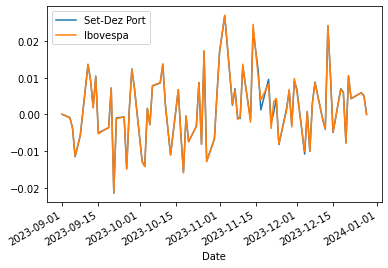

In [17]:
pd.concat([dfRet,dfRetIbov],axis=1).plot()

<AxesSubplot:xlabel='Date'>

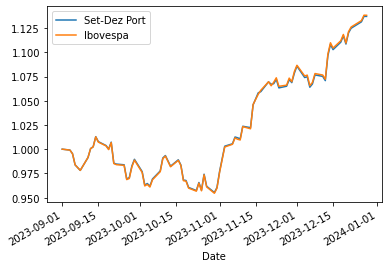

In [18]:
pd.concat([dfRetCum,dfRetIbovCum],axis=1).plot()

In [19]:
dfRetAll = dfAll.copy()

dfRetAll = dfRetAll.pct_change(1)
dfRetAll = dfRetAll.loc['2023-09-01':,:]
dfRetAll.iloc[0,0] = 0.0
dfRetAllCum = dfRetAll.copy()
dfRetAllCum = dfRetAllCum + 1.0
dfRetAllCum = dfRetAllCum.cumprod()


As funfact, below are the stocks that outperformed the index in the last four months:

In [20]:
dfTemp = dfRetAllCum.iloc[-1,:]

mask = dfTemp  > dfRetIbovCum.iloc[-1,:].squeeze()

dfTemp = dfTemp[mask]
print(dfTemp.shape[0])
dfTemp.sort_values()

42


RAIZ4     1.138411
TAEE11    1.140900
ENEV3     1.141778
EMBR3     1.148794
CCRO3     1.152968
ASAI3     1.165375
BPAC11    1.165996
ENGI11    1.167679
PETR3     1.168868
MULT3     1.177113
BBDC4     1.182710
IGTI11    1.183495
BBAS3     1.194231
BBDC3     1.194756
COGN3     1.195205
VALE3     1.198009
ALPA4     1.203329
ELET3     1.203347
SANB11    1.209642
PETR4     1.210734
ELET6     1.212700
CRFB3     1.213450
ITSA4     1.214087
BRAP4     1.221397
TOTS3     1.222004
CPLE6     1.242687
FLRY3     1.254326
ITUB4     1.263723
GOLL4     1.275960
TIMS3     1.278077
VBBR3     1.283636
CIEL3     1.284980
SBSP3     1.301278
MRFG3     1.309042
VIVT3     1.316180
USIM5     1.350291
JBSS3     1.353804
CVCB3     1.411290
UGPA3     1.459802
BRFS3     1.527655
CSNA3     1.701114
CMIN3     1.895693
Name: 2023-12-28 00:00:00, dtype: float64

# Hierarchical Clustering

In [21]:
# prepare the returns

dfret = dfRetAll.copy()
for col in dfRetAll.columns:
    dfret.loc[:,col] = (dfret.loc[:,col] - dfret.loc[:,col].mean())/dfRetAll.loc[:,col].std()

dfretIdx = dfRetIbov.copy()
dfretIdx = (dfretIdx - dfretIdx.mean())/dfretIdx.std()


In [22]:
def plot_corr(df,size=10):
    '''Plot a graphical correlation matrix for a dataframe.

    Input:
        df: pandas DataFrame
        size: vertical and horizontal size of the plot'''
    
    %matplotlib inline
    import matplotlib.pyplot as plt

    # Compute the correlation matrix for the received dataframe
    corr = df.corr()
    
    # Plot the correlation matrix
    fig, ax = plt.subplots(figsize=(size, size))
    cax = ax.matshow(corr, cmap='RdYlGn')
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90);
    plt.yticks(range(len(corr.columns)), corr.columns);
    
    # Add the colorbar legend
    cbar = fig.colorbar(cax, ticks=[-1, 0, 1], aspect=40, shrink=.8)

In [23]:
# Two pass clustering
# 1-We cluster the corr matrix
#   We sort the survey data according to this clustering
# 2-For cluster bigger than a threshold we cluster those sub-clusters
#   We sort the survey data according to these clustering

import scipy
import scipy.cluster.hierarchy as sch
import numpy as np
cluster_th = 5

X = dfret.corr().values
d = sch.distance.pdist(X)
L = sch.linkage(d, method='complete')
ind = sch.fcluster(L, 0.5*d.max(), 'distance')

columns = [dfret.columns.tolist()[i] for i in list(np.argsort(ind))]

listColTemp = dfret.columns.tolist()
dfret = dfret.reindex(columns, axis=1)


dfClusters = pd.DataFrame(ind.copy()).T
dfClusters.columns = listColTemp

unique, counts = np.unique(ind, return_counts=True)
counts = dict(zip(unique, counts))

i = 0
j = 0
columns = []
for cluster_l1 in set(sorted(ind)):
    j += counts[cluster_l1]
    sub = dfret[dfret.columns.values[i:j]]
    if counts[cluster_l1]>cluster_th:        
        X = sub.corr().values
        d = sch.distance.pdist(X)
        L = sch.linkage(d, method='complete')
        ind = sch.fcluster(L, 0.5*d.max(), 'distance')
        col = [sub.columns.tolist()[i] for i in list((np.argsort(ind)))]
        
        listColTemp = sub.columns.tolist()
        sub = sub.reindex(col, axis=1)
        
        dfTemp = pd.DataFrame(ind.copy()).T
        dfTemp.columns = listColTemp
        dfClusters = pd.concat([dfClusters,dfTemp],axis=0)
        
    cols = sub.columns.tolist()
    columns.extend(cols)
    i = j
dfret = dfret.reindex(columns, axis=1)


In [24]:
dfClusters = dfClusters.reset_index(drop=True)
dfClusters

,ABEV3,ALPA4,ARZZ3,ASAI3,AZUL4,B3SA3,BBAS3,BBDC3,BBDC4,BBSE3,...,TIMS3,TOTS3,UGPA3,USIM5,VALE3,VAMO3,VBBR3,VIVT3,WEGE3,YDUQ3
0,2.0,3.0,2.0,2.0,2.0,2.0,3.0,2.0,2.0,4.0,...,3.0,2.0,3.0,4.0,4.0,2.0,3.0,3.0,3.0,3.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,13.0,NaN,6.0,6.0,5.0,2.0,NaN,2.0,2.0,NaN,...,NaN,18.0,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN
3,NaN,13.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,...,1.0,NaN,4.0,NaN,NaN,NaN,3.0,1.0,15.0,7.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,...,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN


Lets check which stocks belong to the first cluster in the first interation:

In [45]:
idx =0 
listCluster = dfClusters.loc[idx,:].unique()
listCluster.sort()
dfCluster = pd.DataFrame()
listPerc = []

for clu in listCluster:
    print('Cluster = ' + str(clu), ' with stocks:')
    mask = dfClusters.loc[idx,:] == clu
    listTickers = list(dfClusters.loc[idx,mask].index)
    
    print(listTickers)
    print('=====> percentual', dfMemb.loc[listTickers,'perc'].sum())
    listPerc.append(dfMemb.loc[listTickers,'perc'].sum())

dfTemp = pd.DataFrame(listPerc,index=listCluster,columns=[idx])
    
if dfCluster.empty:
    dfCluster = dfTemp.copy()
else:
    dfCluster = pd.concat([dfCluster,dfTemp],aixs=1)
dfCluster

Cluster = 1.0  with stocks:
['BRKM5', 'KLBN11', 'PETR3', 'PETR4', 'PRIO3', 'SUZB3']
=====> percentual 16.264
Cluster = 2.0  with stocks:
['ABEV3', 'ARZZ3', 'ASAI3', 'AZUL4', 'B3SA3', 'BBDC3', 'BBDC4', 'BPAC11', 'CCRO3', 'COGN3', 'CPFE3', 'CPLE6', 'CRFB3', 'CSAN3', 'CYRE3', 'DXCO3', 'EGIE3', 'ELET3', 'ELET6', 'ENEV3', 'ENGI11', 'EQTL3', 'EZTC3', 'FLRY3', 'HAPV3', 'HYPE3', 'IGTI11', 'ITSA4', 'ITUB4', 'LREN3', 'MRVE3', 'MULT3', 'PCAR3', 'PETZ3', 'RADL3', 'RAIL3', 'RDOR3', 'RENT3', 'SANB11', 'SBSP3', 'SOMA3', 'TAEE11', 'TOTS3', 'VAMO3']
=====> percentual 48.222
Cluster = 3.0  with stocks:
['ALPA4', 'BBAS3', 'CIEL3', 'CMIG4', 'CVCB3', 'EMBR3', 'GOLL4', 'IRBR3', 'JBSS3', 'LWSA3', 'MGLU3', 'NTCO3', 'RAIZ4', 'SLCE3', 'TIMS3', 'UGPA3', 'VBBR3', 'VIVT3', 'WEGE3', 'YDUQ3']
=====> percentual 14.302999999999999
Cluster = 4.0  with stocks:
['BBSE3', 'BEEF3', 'BRAP4', 'BRFS3', 'CMIN3', 'CSNA3', 'GGBR4', 'GOAU4', 'MRFG3', 'RECV3', 'RRRP3', 'SMTO3', 'USIM5', 'VALE3']
=====> percentual 20.518


,0
1.0,16.264
2.0,48.222
3.0,14.303
4.0,20.518


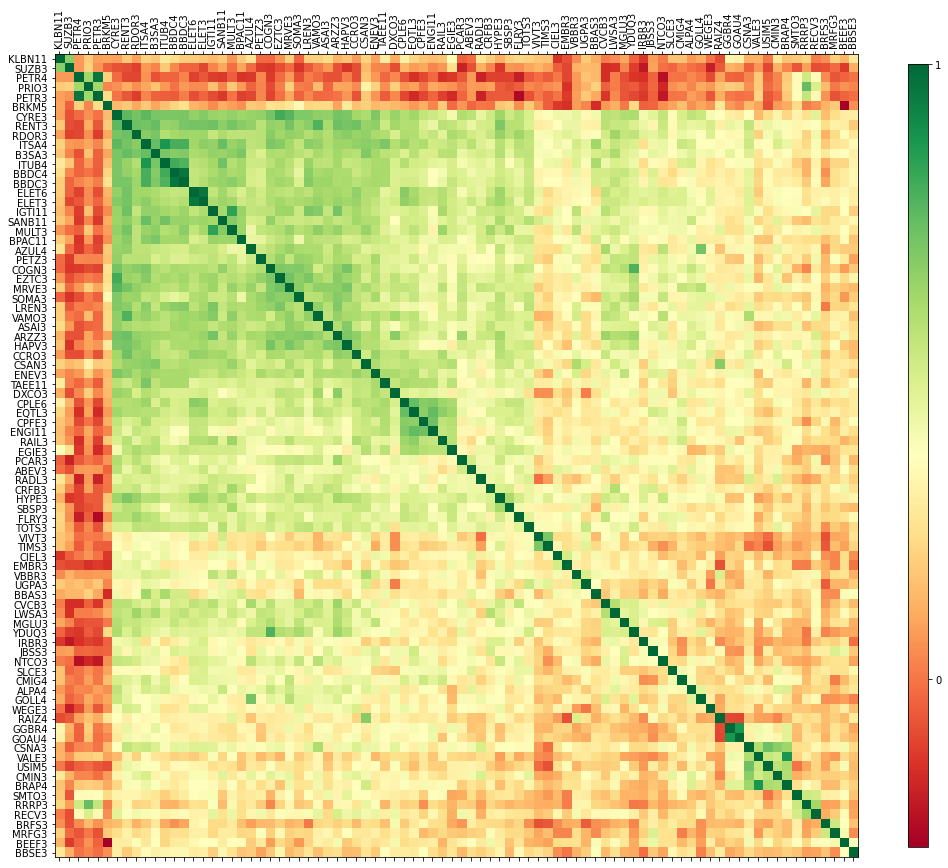

In [26]:
plot_corr(dfret, 18)

In [27]:
idx = 0
cluster = 1.0
dfRetCluster = pd.DataFrame()
for cluster in dfClusters.loc[idx,:].unique():
    mask = dfClusters.loc[idx,:] == cluster
    listCuster = mask[mask].index.tolist()
    dfTemp = dfret.loc[:,listCuster].copy()/len(listCuster)
    dfTemp = dfTemp.sum(axis=1)
    dfTemp = pd.DataFrame(dfTemp,columns=[cluster])
    if dfRetCluster.empty:
        dfRetCluster = dfTemp.copy()
    else:
        dfRetCluster = pd.concat([dfRetCluster,dfTemp], axis=1)
dfRetCluster

,2.0,3.0,4.0,1.0
Date,,,,
2023-09-01,0.639706,0.600701,1.000871,0.914837
2023-09-04,-0.167263,-0.075752,0.552999,-0.265762
2023-09-05,-0.834946,-0.562388,-0.494787,0.629169
2023-09-06,-0.945396,-0.553678,-0.830286,-0.234269
2023-09-08,-0.140143,-0.463829,-0.429960,-0.396880
...,...,...,...,...
2023-12-21,0.300363,0.039007,0.773550,0.614405
2023-12-22,0.216827,0.117381,0.070395,0.534379
2023-12-26,0.083047,0.167816,0.236764,0.446062


In [28]:

X = dfRetCluster.copy()
y = dfretIdx.copy()

import statsmodels.api as sm
X = sm.add_constant(X) # manually add a constant here
# X = sm.add_constant(X)
model = sm.OLS(y,X)
results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Ibovespa   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.903
Method:                 Least Squares   F-statistic:                     183.9
Date:                Wed, 03 Jan 2024   Prob (F-statistic):           6.02e-38
Time:                        22:59:19   Log-Likelihood:                -17.802
No. Observations:                  80   AIC:                             45.60
Df Residuals:                      75   BIC:                             57.52
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2.082e-17      0.035  -5.96e-16      1.000      -0.070       0.070
2.0            0.7029      0.115      6.121      0.000       0.474       0.932
3.0            0.3484      0.142      2.450      0.017       0.065       0.632
4.0            0.4306      0.084      5.145      0.000       0.264       0.597
1.0            0.3906      0.060      6.549      0.000       0.272       0.509
==============================================================================
Omnibus:                       50.842   Durbin-Watson:                   1.677
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              298.077
Skew:                          -1.776   Prob(JB):                     1.88e-65
Kurtosis:                      11.764   Cond. No.                         5.03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [46]:
dfCoefRenorm = pd.DataFrame(results.params,columns=['coef mult'])
dfCoefRenorm = dfCoefRenorm/dfCoefRenorm.sum()


,coef,0
1.0,0.208591,16.264
2.0,0.375394,48.222
3.0,0.186065,14.303
4.0,0.229949,20.518


In [61]:
dfCoefUni = pd.DataFrame()
for col in dfRetCluster.columns:
    X = dfRetCluster.loc[:,[col]].copy()

    y = dfretIdx.copy()

    import statsmodels.api as sm
    X = sm.add_constant(X) # manually add a constant here
    # X = sm.add_constant(X)
    model = sm.OLS(y,X)
    results = model.fit()
    dfTemp = pd.DataFrame(results.params,columns=['coef uni'])
    print(dfTemp)
    dfTemp = dfTemp.drop('const',axis=0)
    if dfCoefUni.empty:
        dfCoefUni = dfTemp.copy()
    else:
        dfCoefUni = pd.concat([dfCoefUni,dfTemp],axis=0)
dfCoefUni = dfCoefUni/dfCoefUni.sum()
dfCoefUni = dfCoefUni.sort_index()
    

           coef uni
const -1.734723e-17
2.0    1.197189e+00
           coef uni
const -1.734723e-17
3.0    1.456737e+00
           coef uni
const -1.734723e-17
4.0    1.332169e+00
           coef uni
const -1.734723e-17
1.0    5.951727e-01


,coef uni
1.0,0.129914
2.0,0.261323
3.0,0.317977
4.0,0.290786


In [59]:
pd.concat([dfCoefRenorm.drop('const',axis=0).sort_index(),dfCoefUni,dfCluster],axis=1)

,coef,coef uni,0
1.0,0.208591,0.129914,16.264
2.0,0.375394,0.261323,48.222
3.0,0.186065,0.317977,14.303
4.0,0.229949,0.290786,20.518


In [43]:
idx =0 
listCluster = dfClusters.loc[idx,:].unique()
listCluster.sort()
for clu in listCluster:
    print('Cluster = ' + str(clu))
    mask = dfClusters.loc[idx,:] == clu
    listTickers = list(dfClusters.loc[idx,mask].index)
    
    print(listTickers)
    print('=====> percentual', dfMemb.loc[listTickers,'perc'].sum())

Cluster = 1.0
['BRKM5', 'KLBN11', 'PETR3', 'PETR4', 'PRIO3', 'SUZB3']
=====> percentual 16.264
Cluster = 2.0
['ABEV3', 'ARZZ3', 'ASAI3', 'AZUL4', 'B3SA3', 'BBDC3', 'BBDC4', 'BPAC11', 'CCRO3', 'COGN3', 'CPFE3', 'CPLE6', 'CRFB3', 'CSAN3', 'CYRE3', 'DXCO3', 'EGIE3', 'ELET3', 'ELET6', 'ENEV3', 'ENGI11', 'EQTL3', 'EZTC3', 'FLRY3', 'HAPV3', 'HYPE3', 'IGTI11', 'ITSA4', 'ITUB4', 'LREN3', 'MRVE3', 'MULT3', 'PCAR3', 'PETZ3', 'RADL3', 'RAIL3', 'RDOR3', 'RENT3', 'SANB11', 'SBSP3', 'SOMA3', 'TAEE11', 'TOTS3', 'VAMO3']
=====> percentual 48.222
Cluster = 3.0
['ALPA4', 'BBAS3', 'CIEL3', 'CMIG4', 'CVCB3', 'EMBR3', 'GOLL4', 'IRBR3', 'JBSS3', 'LWSA3', 'MGLU3', 'NTCO3', 'RAIZ4', 'SLCE3', 'TIMS3', 'UGPA3', 'VBBR3', 'VIVT3', 'WEGE3', 'YDUQ3']
=====> percentual 14.302999999999999
Cluster = 4.0
['BBSE3', 'BEEF3', 'BRAP4', 'BRFS3', 'CMIN3', 'CSNA3', 'GGBR4', 'GOAU4', 'MRFG3', 'RECV3', 'RRRP3', 'SMTO3', 'USIM5', 'VALE3']
=====> percentual 20.518


In [29]:
dfPerc = dfNotional.copy()

for col in dfNotional.columns:
    dfPerc.loc[:,col] = dfNotional.loc[:,col] /dfNotional.sum(axis=1)
dfPerc.loc[:,'PETR4']

Date
2023-01-02    0.043961
2023-01-03    0.043725
2023-01-04    0.044634
2023-01-05    0.045293
2023-01-06    0.044461
                ...   
2023-12-21    0.073788
2023-12-22    0.074183
2023-12-26    0.074932
2023-12-27    0.074620
2023-12-28    0.074382
Name: PETR4, Length: 248, dtype: float64